# Study-robust selection among the original eight LightGBM settings

**historical_hypothetical_unit_scenario**. Historical units remain unverified. All five outer outcomes were already inspected; this is exploratory, not independent validation. S1/S2 are specified by the prompt, not learned from blending outcomes. Maximum ten new outer fits; no inner fitting or architecture searches.

## 1. Setup, environment and global fit-call guard

In [1]:
import json,sys
from pathlib import Path
from IPython.display import display,Markdown,SVG
ROOT=Path.cwd();OUT=ROOT/'study_robustness_outputs'
sys.dont_write_bytecode=True
sys.path.insert(0,str(OUT/'source'));sys.path.insert(0,str(OUT/'tests'))
from audit import Context
from fit_budget import FitBudget,refit_locked
from evaluation import evaluate
from reporting import figures,compose,fit_accounting
from test_stage4 import run_tests
ctx=Context(OUT);budget=FitBudget(OUT);budget.__enter__()
print('Repository:',ROOT)
print((OUT/'environment.json').read_text())
print('Protected paths:',len(json.loads((OUT/'protected_hashes_before.json').read_text())))

Repository: /Users/gourabadhikari/Desktop/marine-microplastics-baseline
{
  "python": "3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 08:22:19) [Clang 14.0.6 ]",
  "executable": "/Users/gourabadhikari/Desktop/marine-microplastics-baseline/reproduction_outputs/venv/bin/python",
  "platform": "macOS-15.6.1-arm64-arm-64bit",
  "cpu_count": 8,
  "threads": 4,
  "seed": 0,
  "packages": {
    "numpy": "2.5.3",
    "pandas": "3.0.6",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "lightgbm": "4.7.0",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0"
  },
  "downloads": 0
}
Protected paths: 27249


## 2. Read-only source, data, reference, configuration and split audit

In [2]:
display(ctx.load())
print('Identical row IDs, labels, scenario and folds verified. No historical fits rerun.')
print('New fits this kernel:',budget.calls_this_process)

29,076 records, 96 accessions, 68 organisations
16,988 records, 73 accessions, 73 publications, 72 studies, 52 organisations


,outer,candidate,scenario,R2,study_macro_MAE,p90_study_MAE,worst_study_MAE
0,1,C0_original,historical_hypothetical_unit_scenario,0.263321,1.043282,1.801435,5.073595
1,1,C1_shallow,historical_hypothetical_unit_scenario,0.315986,1.002632,1.842928,4.663971
2,1,C2_conservative,historical_hypothetical_unit_scenario,0.365954,1.025249,1.759184,4.876067
3,1,C3_strong_regularization,historical_hypothetical_unit_scenario,0.327485,1.010798,1.885082,5.016062
4,1,C4_feature_subsample,historical_hypothetical_unit_scenario,0.355924,0.984688,1.671201,4.911475
5,1,C5_row_and_feature_subsample,historical_hypothetical_unit_scenario,0.370773,0.983540,1.639421,4.815156
6,1,C6_slower,historical_hypothetical_unit_scenario,0.343790,1.021137,1.961198,4.740560
7,1,C7_fewer_trees,historical_hypothetical_unit_scenario,0.378952,1.009362,1.995063,4.799377
8,2,C0_original,historical_hypothetical_unit_scenario,0.290914,1.169923,2.248300,5.685899
9,2,C1_shallow,historical_hypothetical_unit_scenario,0.487679,1.054771,2.007720,4.974799


Identical row IDs, labels, scenario and folds verified. No historical fits rerun.
New fits this kernel: 0


## 3. Reconstruct saved inner OOF metrics and verify all training studies

In [3]:
print(json.dumps(ctx.verify_inner_cache(),indent=2))
print('New fits this kernel:',budget.calls_this_process)
assert budget.calls_this_process==0

{
  "inner_checkpoints_verified": 120,
  "optimized_outer_checkpoints_verified": 5,
  "new_fits": 0,
  "max_metric_difference": 0.0,
  "provenance": "Exact prior key rebuilt from code/data/splits/configs/versions and training-only labels; inner validation covers every outer-training row once; all study groups counted."
}
New fits this kernel: 0


## 4. Freeze S1 and S2 choices before any new outer prediction

In [4]:
display(ctx.lock())
print('Pre-fit timestamp:',ctx.locked['created_utc'])
print('Locked selection payload hash:',ctx.locked['payload_sha256'])
import pandas as pd
display(pd.read_csv(OUT/'selector_eligibility.csv'))
assert budget.calls_this_process==0

,rule,outer,candidate,eligible_count,contender_count
0,S1,1,C5_row_and_feature_subsample,4,4
1,S1,2,C1_shallow,4,4
2,S1,3,C4_feature_subsample,2,2
3,S1,4,C4_feature_subsample,3,3
4,S1,5,C5_row_and_feature_subsample,3,3
5,S2,1,C5_row_and_feature_subsample,5,2
6,S2,2,C5_row_and_feature_subsample,5,2
7,S2,3,C4_feature_subsample,3,2
8,S2,4,C4_feature_subsample,5,1
9,S2,5,C4_feature_subsample,3,2


Pre-fit timestamp: 2026-11-16T08:21:40.807333+00:00
Locked selection payload hash: 6d79ce9912512dd729c49459432f46f64d88344a299ed79efe981812579cb412


,outer,candidate,scenario,R2,study_macro_MAE,p90_study_MAE,worst_study_MAE,r2_pass,macro_pass,p90_pass,worst_pass,eligible,best_r2_band_pass,rule,selected,reason
0,1,C0_original,historical_hypothetical_unit_scenario,0.263321,1.043282,1.801435,5.073595,True,True,True,True,True,True,S1,False,eligible; loses frozen lexicographic order
1,1,C1_shallow,historical_hypothetical_unit_scenario,0.315986,1.002632,1.842928,4.663971,True,True,False,True,False,True,S1,False,ineligible: p90_pass
2,1,C2_conservative,historical_hypothetical_unit_scenario,0.365954,1.025249,1.759184,4.876067,True,True,True,True,True,True,S1,False,eligible; loses frozen lexicographic order
3,1,C3_strong_regularization,historical_hypothetical_unit_scenario,0.327485,1.010798,1.885082,5.016062,True,True,False,True,False,True,S1,False,ineligible: p90_pass
4,1,C4_feature_subsample,historical_hypothetical_unit_scenario,0.355924,0.984688,1.671201,4.911475,True,True,True,True,True,True,S1,False,eligible; loses frozen lexicographic order
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,5,C3_strong_regularization,historical_hypothetical_unit_scenario,0.481607,1.026387,2.072032,3.032648,False,True,True,True,False,False,S2,False,ineligible: r2_pass
76,5,C4_feature_subsample,historical_hypothetical_unit_scenario,0.512771,1.022650,1.995699,4.351699,True,True,True,True,True,True,S2,True,selected by frozen lexicographic order
77,5,C5_row_and_feature_subsample,historical_hypothetical_unit_scenario,0.512797,1.038485,1.894881,3.922200,True,True,True,True,True,True,S2,False,eligible; loses frozen lexicographic order
78,5,C6_slower,historical_hypothetical_unit_scenario,0.529574,1.021010,2.139550,4.712478,True,True,False,True,False,True,S2,False,ineligible: p90_pass


## 5. Exact locked outer refits and verified reference/checkpoint reuse

In [5]:
display(refit_locked(ctx,budget).head())
print(json.dumps(fit_accounting(ctx),indent=2))
print('Fit guard now closes new calls. Outer metrics cannot trigger any further training.')

S1 fold 1: C5_row_and_feature_subsample [stage4_checkpoint]


S1 fold 2: C1_shallow [optimized_frozen_OOF]


S1 fold 3: C4_feature_subsample [stage4_checkpoint]


S1 fold 4: C4_feature_subsample [optimized_frozen_OOF]


S1 fold 5: C5_row_and_feature_subsample [stage4_checkpoint]


S2 fold 1: C5_row_and_feature_subsample [stage4_checkpoint]


... (2 outputs left out)

S2 fold 4: C4_feature_subsample [optimized_frozen_OOF]


S2 fold 5: C4_feature_subsample [stage4_checkpoint]


,water_row,source_row,study,doi,accession,fold,target_log10,method_family,study_size,study_size_bin,scenario,original_C0,previously_optimized,S1,S2,S1_candidate,S2_candidate
0,0,0,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.128217,surface net,6135,1001+,historical_hypothetical_unit_scenario,-2.451774,-2.762704,-2.415442,-2.415442,C5_row_and_feature_subsample,C5_row_and_feature_subsample
1,1,1,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-0.830126,surface net,6135,1001+,historical_hypothetical_unit_scenario,-2.485834,-2.767258,-2.561383,-2.561383,C5_row_and_feature_subsample,C5_row_and_feature_subsample
2,2,2,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.928118,surface net,6135,1001+,historical_hypothetical_unit_scenario,-2.485834,-2.767258,-2.561383,-2.561383,C5_row_and_feature_subsample,C5_row_and_feature_subsample
3,3,3,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.423474,surface net,6135,1001+,historical_hypothetical_unit_scenario,-2.473610,-2.762704,-2.415442,-2.415442,C5_row_and_feature_subsample,C5_row_and_feature_subsample
4,4,4,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.606249,surface net,6135,1001+,historical_hypothetical_unit_scenario,-2.473610,-2.762704,-2.415442,-2.415442,C5_row_and_feature_subsample,C5_row_and_feature_subsample


{
  "new_fits_started_total": 5,
  "new_fits_completed_total": 5,
  "failed_fits": 0,
  "initial_routes": {
    "fresh_fit": 5,
    "optimized_frozen_OOF": 3,
    "stage4_checkpoint": 2
  },
  "current_routes": {
    "stage4_checkpoint": 7,
    "optimized_frozen_OOF": 3
  },
  "warnings": []
}
Fit guard now closes new calls. Outer metrics cannot trigger any further training.


## 6. Four-procedure paired evaluation and frozen descriptive screen

In [6]:
display(evaluate(ctx))
print((OUT/'screening.json').read_text())
display(pd.read_csv(OUT/'paired_fold_metrics.csv')[['fold','procedure','rows','studies','R2','MAE','RMSE']])

,procedure,rows,studies,scenario,R2,MAE,RMSE,study_macro_MAE,study_macro_MSE,median_study_MAE,...,delta_vs_previously_optimized__MAE,delta_vs_previously_optimized__RMSE,delta_vs_previously_optimized__study_macro_MAE,delta_vs_previously_optimized__study_macro_MSE,delta_vs_previously_optimized__median_study_MAE,delta_vs_previously_optimized__p90_study_MAE,delta_vs_previously_optimized__worst_study_MAE,delta_vs_previously_optimized__within_1_log,delta_vs_previously_optimized__mean_fold_R2,within_1_log_percent
0,original_C0,16988,72,historical_hypothetical_unit_scenario,0.472631,0.996377,1.418198,1.060942,2.171751,0.866895,...,-0.012965,0.041968,0.059531,0.141676,0.035222,-0.087826,-0.351901,0.029315,0.009441,63.939251
1,previously_optimized,16988,72,historical_hypothetical_unit_scenario,0.503381,1.009343,1.376230,1.001411,2.030075,0.831673,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,61.007770
2,S1,16988,72,historical_hypothetical_unit_scenario,0.519492,0.995283,1.353723,0.980533,1.959111,0.803530,...,-0.014060,-0.022507,-0.020878,-0.070964,-0.028143,-0.068198,-0.051242,0.012126,0.025632,62.220391
3,S2,16988,72,historical_hypothetical_unit_scenario,0.525628,0.991547,1.345052,0.999354,1.969287,0.842640,...,-0.017796,-0.031178,-0.002058,-0.060788,0.010967,-0.114815,-0.129949,0.018248,0.043412,62.832588


{
  "S1": {
    "passed": true,
    "conditions": {
      "pooled_R2_at_least_0.4883812847921568": true,
      "study_macro_MAE_no_worse": true,
      "p90_study_MAE_no_worse": true,
      "worst_study_MAE_no_worse": true
    },
    "failed_conditions": [],
    "interpretation": "Descriptive screen on reused outcomes only; no reselection or promotion authorized."
  },
  "S2": {
    "passed": true,
    "conditions": {
      "pooled_R2_at_least_0.4883812847921568": true,
      "study_macro_MAE_no_worse": true,
      "p90_study_MAE_no_worse": true,
      "worst_study_MAE_no_worse": true
    },
    "failed_conditions": [],
    "interpretation": "Descriptive screen on reused outcomes only; no reselection or promotion authorized."
  }
}


,fold,procedure,rows,studies,R2,MAE,RMSE
0,1,original_C0,6135,1,-0.555996,0.727919,0.909012
1,1,previously_optimized,6135,1,-0.498304,0.719173,0.892001
2,1,S1,6135,1,-0.431151,0.717710,0.871782
3,1,S2,6135,1,-0.431151,0.717710,0.871782
4,2,original_C0,2714,11,0.003502,0.812758,1.003800
5,2,previously_optimized,2714,11,-0.468474,1.002473,1.218546
6,2,S1,2714,11,-0.468474,1.002473,1.218546
7,2,S2,2714,11,-0.424101,1.018206,1.199995
8,3,original_C0,2712,20,0.301706,1.602672,2.273102
9,3,previously_optimized,2712,20,0.376104,1.596711,2.148602


## 7. All-study harms, method/size summaries and largest-study influence

,procedure,reference,studies_worse,studies_worse_over_0_10,studies_better,studies_equal,scenario
0,S1,original_C0,30,12,42,0,historical_hypothetical_unit_scenario
1,S1,previously_optimized,15,6,26,31,historical_hypothetical_unit_scenario
2,S2,original_C0,33,17,39,0,historical_hypothetical_unit_scenario
3,S2,previously_optimized,26,10,26,20,historical_hypothetical_unit_scenario


,study,fold,procedure,rows,method_families,scenario,MAE,MSE,RMSE,within_1_log,delta_vs_original_C0__MAE,delta_vs_original_C0__MSE,delta_vs_original_C0__RMSE,delta_vs_original_C0__within_1_log,delta_vs_previously_optimized__MAE,delta_vs_previously_optimized__MSE,delta_vs_previously_optimized__RMSE,delta_vs_previously_optimized__within_1_log
0,https://doi.org/10.1007/s00128-022-03620-5,4,original_C0,8,surface net,historical_hypothetical_unit_scenario,1.013701,1.224909,1.106756,0.500000,0.000000,0.000000,0.000000,0.000000,0.156696,0.293133,0.141470,0.000000
1,https://doi.org/10.1007/s00128-022-03620-5,4,previously_optimized,8,surface net,historical_hypothetical_unit_scenario,0.857004,0.931776,0.965286,0.500000,-0.156696,-0.293133,-0.141470,0.000000,0.000000,0.000000,0.000000,0.000000
2,https://doi.org/10.1007/s00128-022-03620-5,4,S1,8,surface net,historical_hypothetical_unit_scenario,0.857004,0.931776,0.965286,0.500000,-0.156696,-0.293133,-0.141470,0.000000,0.000000,0.000000,0.000000,0.000000
3,https://doi.org/10.1007/s00128-022-03620-5,4,S2,8,surface net,historical_hypothetical_unit_scenario,0.857004,0.931776,0.965286,0.500000,-0.156696,-0.293133,-0.141470,0.000000,0.000000,0.000000,0.000000,0.000000
4,https://doi.org/10.1007/s10661-022-10468-z,3,original_C0,72,surface net,historical_hypothetical_unit_scenario,2.754659,7.799861,2.792823,0.000000,0.000000,0.000000,0.000000,0.000000,0.318238,1.628353,0.308571,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,https://doi.org/10.3389/fmars.2021.699000,5,S2,76,surface net,historical_hypothetical_unit_scenario,0.522186,0.450636,0.671294,0.855263,-0.024396,-0.079496,-0.056807,0.026316,-0.013650,-0.050749,-0.036791,0.013158
284,https://doi.org/10.3389/fmars.2022.784937,3,original_C0,71,surface net,historical_hypothetical_unit_scenario,0.433468,0.309874,0.556663,0.915493,0.000000,0.000000,0.000000,0.000000,-0.013879,-0.041023,-0.035703,0.014085
285,https://doi.org/10.3389/fmars.2022.784937,3,previously_optimized,71,surface net,historical_hypothetical_unit_scenario,0.447347,0.350897,0.592366,0.901408,0.013879,0.041023,0.035703,-0.014085,0.000000,0.000000,0.000000,0.000000
286,https://doi.org/10.3389/fmars.2022.784937,3,S1,71,surface net,historical_hypothetical_unit_scenario,0.493405,0.402418,0.634364,0.887324,0.059937,0.092544,0.077701,-0.028169,0.046058,0.051520,0.041998,-0.014085


,grouping,group,procedure,rows,studies,scenario,R2,MAE,RMSE,study_macro_MAE,...,delta_vs_original_C0__within_1_log,delta_vs_previously_optimized__R2,delta_vs_previously_optimized__MAE,delta_vs_previously_optimized__RMSE,delta_vs_previously_optimized__study_macro_MAE,delta_vs_previously_optimized__study_macro_MSE,delta_vs_previously_optimized__median_study_MAE,delta_vs_previously_optimized__p90_study_MAE,delta_vs_previously_optimized__worst_study_MAE,delta_vs_previously_optimized__within_1_log
0,method_family,bulk water,original_C0,1903,12,historical_hypothetical_unit_scenario,-0.041714,2.053115,2.727677,1.383764,...,0.000000,-0.044366,-0.108160,0.058717,-0.129420,-0.477810,-0.395005,-0.626301,-0.065635,0.115081
1,method_family,bulk water,previously_optimized,1903,12,historical_hypothetical_unit_scenario,0.002652,2.161275,2.668960,1.513184,...,-0.115081,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,method_family,bulk water,S1,1903,12,historical_hypothetical_unit_scenario,0.023277,2.121622,2.641219,1.564592,...,-0.107199,0.020625,-0.039653,-0.027741,0.051408,0.351251,-0.016942,0.283049,0.285902,0.007882
3,method_family,bulk water,S2,1903,12,historical_hypothetical_unit_scenario,0.023059,2.124125,2.641513,1.584553,...,-0.107199,0.020408,-0.037151,-0.027447,0.071369,0.369175,-0.000406,0.283049,0.285902,0.007882
4,method_family,pump,original_C0,852,6,historical_hypothetical_unit_scenario,-1.331179,1.299307,1.552286,1.228086,...,0.000000,-0.688936,0.264500,0.249411,0.050661,0.214858,0.093075,0.083983,0.292852,-0.206573
5,method_family,pump,previously_optimized,852,6,historical_hypothetical_unit_scenario,-0.642243,1.034807,1.302874,1.177425,...,0.206573,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,method_family,pump,S1,852,6,historical_hypothetical_unit_scenario,-0.833849,1.083491,1.376783,1.292269,...,0.181925,-0.191606,0.048684,0.073909,0.114845,0.461707,0.042708,0.308997,0.601894,-0.024648
7,method_family,pump,S2,852,6,historical_hypothetical_unit_scenario,-0.710863,1.053606,1.329816,1.267177,...,0.190141,-0.068620,0.018799,0.026941,0.089752,0.308076,0.057029,0.213314,0.281699,-0.016432
8,method_family,surface net,original_C0,14233,58,historical_hypothetical_unit_scenario,0.093210,0.836954,1.123198,1.010207,...,0.000000,-0.039520,-0.016847,0.024748,0.099748,0.237814,0.097320,0.063722,-0.351901,0.031968
9,method_family,surface net,previously_optimized,14233,58,historical_hypothetical_unit_scenario,0.132730,0.853801,1.098450,0.910459,...,-0.031968,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


{
  "scenario": "historical_hypothetical_unit_scenario",
  "study": "https://doi.org/10.1126/science.1192321",
  "rows": 6135,
  "row_fraction": 0.36113727336943724,
  "diagnostic_only": "No exclusion from primary benchmark and no refitting.",
  "original_C0": {
    "total_SSE": 34167.70623682302,
    "largest_SSE_fraction": 0.14836710939665762,
    "largest_study_R2": -0.5559959335804521,
    "excluding_largest_R2": 0.42621569179763175,
    "delta_R2_vs_original_C0_from_largest": 0.0,
    "delta_R2_vs_original_C0_from_remaining": 0.0,
    "delta_R2_vs_previously_optimized_from_largest": -0.002901070322317842,
    "delta_R2_vs_previously_optimized_from_remaining": -0.027849374610641752
  },
  "previously_optimized": {
    "total_SSE": 32175.41649268924,
    "largest_SSE_fraction": 0.15171230009159786,
    "largest_study_R2": -0.49830409904859785,
    "excluding_largest_R2": 0.4617949557231812,
    "delta_R2_vs_original_C0_from_largest": 0.002901070322317842,
    "delta_R2_vs_original_C

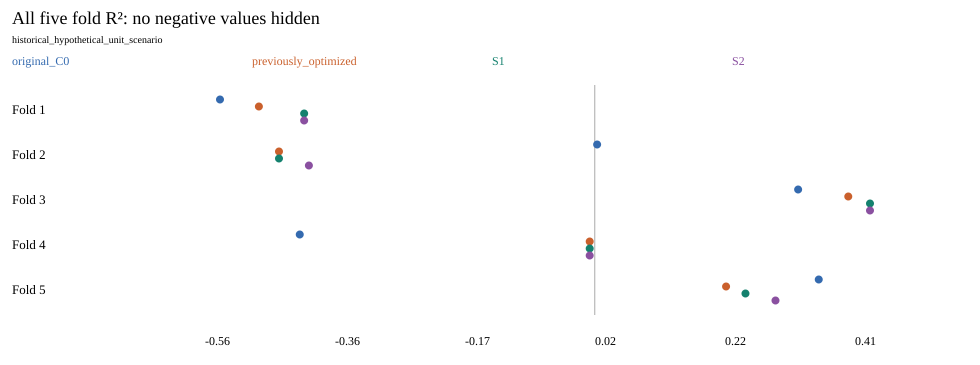

In [7]:
display(pd.read_csv(OUT/'study_harm_counts.csv'))
display(pd.read_csv(OUT/'paired_study_metrics.csv'))
display(pd.read_csv(OUT/'method_and_study_size_metrics.csv'))
print((OUT/'largest_study_influence.json').read_text())
display(SVG(filename=str(figures(ctx))))

## 8. Tests and final protected-file verification — no new fits

In [8]:
test_status=run_tests(ctx,budget)
print(json.dumps(test_status,indent=2))
print('New fit calls this kernel:',budget.calls_this_process)
print('Original source/data and all three previous output directories unchanged.')

test_C0_fallback_zero_errors_and_nonfinite (test_stage4.Stage4Tests.test_C0_fallback_zero_errors_and_nonfinite) ... ok
test_actual_fitted_preprocessing_training_only (test_stage4.Stage4Tests.test_actual_fitted_preprocessing_training_only) ... ok
test_audited_inner_predictions_count_all_studies (test_stage4.Stage4Tests.test_audited_inner_predictions_count_all_studies) ... ok
test_checkpoint_identity_and_corruption_rejection (test_stage4.Stage4Tests.test_checkpoint_identity_and_corruption_rejection) ... ok
test_exact_oof_alignment_and_coverage (test_stage4.Stage4Tests.test_exact_oof_alignment_and_coverage) ... ok
test_fit_cap_and_no_post_evaluation_fit_allowed (test_stage4.Stage4Tests.test_fit_cap_and_no_post_evaluation_fit_allowed) ... ok
test_frozen_screen_and_largest_study_contribution (test_stage4.Stage4Tests.test_frozen_screen_and_largest_study_contribution) ... ok
test_inclusive_guard_boundaries (test_stage4.Stage4Tests.test_inclusive_guard_boundaries) ... ok
test_independent_s1_s2

## 9. Report rendering and stop

In [9]:
report_text=compose(ctx,test_status,9)
(OUT/'checkpoints/report_ready.md').write_text(report_text)
display(Markdown(report_text))
print('No further model runs permitted. Runner saves notebook/status and writes final report last.')
budget.__exit__(None,None,None)

# Stage 4: study-robust selection among the same eight LightGBM settings

**Scenario throughout: `historical_hypothetical_unit_scenario`.** Barrows (1,389 rows) and Dehm (81 rows) retain the historical ×10^6 multipliers solely to match the benchmark. These are unverified hypotheses, not certified corrections or verified true synthetic microplastic abundance. No target, study, feature or measurement was changed.

## Result and decision

Immutable original pooled R²: **0.4726308398591973**. Immutable previously optimized pooled R²: **0.5033812847921568**.

- **S1**: pooled R² **0.5194916146841499**; Δ original **+0.0468607748249527**, Δ optimized **+0.0161103298919931**. Screen: **PASS**; failed conditions: none.
- **S2**: pooled R² **0.5256280075581679**; Δ original **+0.0529971676989706**, Δ optimized **+0.0222467227660110**. Screen: **PASS**; failed conditions: none.

Promising exploratory candidate(s) under the frozen screen: **S1, S2**. This is not independent confirmation or authorization to deploy/promote a model.

Passing this screen does **not** mean every study or reference comparison improved. Relative to the original baseline, both selectors retain higher worst-study MAE and lower within-one-log coverage; S1 also has a slightly higher p90 study MAE. S2 has a higher median study MAE than the previously optimized procedure. Against the optimized reference, 15 studies worsen under S1 and 26 under S2. All three negative-R² outer folds remain visible, and both mean-fold R² values remain negative. Neither strategy is automatically selected for deployment.

All four procedures use the **same** 16,988 observations, 72 linked studies, log10(concentration + 0.001) targets and five frozen outer folds. They are not independent test sets. The labels/outcomes have been inspected repeatedly; these are exploratory reused-benchmark comparisons, not independent study generalization or production readiness.

## Complete pooled and study-balanced metrics

| procedure | R2 | MAE | RMSE | study_macro_MAE | study_macro_MSE | median_study_MAE | p90_study_MAE | worst_study_MAE | within_1_log_percent | mean_fold_R2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| original_C0 | 0.472630840 | 0.996377423 | 1.418197731 | 1.060942164 | 2.171751369 | 0.866894949 | 1.813391314 | 4.943934893 | 63.939251236 | -0.071234992 |
| previously_optimized | 0.503381285 | 1.009342570 | 1.376229816 | 1.001411331 | 2.030074980 | 0.831673076 | 1.901217782 | 5.295836118 | 61.007770191 | -0.080676231 |
| S1 | 0.519491615 | 0.995282641 | 1.353723309 | 0.980533172 | 1.959111361 | 0.803530141 | 1.833019340 | 5.244593780 | 62.220390864 | -0.055044517 |
| S2 | 0.525628008 | 0.991546912 | 1.345051587 | 0.999353649 | 1.969286989 | 0.842639680 | 1.786402450 | 5.165887296 | 62.832587709 | -0.037263820 |

All errors are on the log10 target. R² is not accuracy. The tolerance percentage is the fraction within ±1 log10 unit of **concentration + 0.001**, not an unqualified percentage correct. Pooled R² uses all OOF predictions together; mean fold R² uses five different fold-specific denominators. Study-macro MAE/MSE weight all 72 studies equally; median/p90 use linear-interpolated quantiles.

## Frozen selectors and audit trail

Only the original eight C0–C7 configurations were available. Full parameters remain in the protected `optimization_outputs/candidate_registry.json`; its hash, exact original feature pipeline and seed/thread settings are recorded in each fit identity. No new parameter settings were invented.

**S1 — Tail-first guarded:** eligible iff inner R² ≥ C0 R² − 0.010; macro MAE ≤1.02×C0; p90 MAE ≤C0; worst MAE ≤1.05×C0. Order: lowest p90, lowest macro MAE, highest R², then smallest candidate ID.

**S2 — Balanced guarded:** eligible iff inner R² ≥ C0 R² −0.010; macro MAE ≤1.03×C0; p90 MAE ≤1.03×C0; worst MAE ≤1.10×C0. Keep candidates within 0.010 of the highest eligible inner R², then order by lowest macro MAE, lowest p90, highest R², smallest ID.

C0 is always eligible for valid finite inputs. There is no division by a baseline error: a zero C0 error implies a zero permitted error bound; undefined/nonfinite or negative errors fail safely. Exact comparisons, no outcome-dependent epsilon or threshold adjustment. Stable candidate-ID tie-breaks are tested.

| selector | fold | candidate | eligible | inner_R2 | inner_macro_MAE | inner_p90_MAE | inner_worst_MAE |
| --- | --- | --- | --- | --- | --- | --- | --- |
| S1 | 1 | C5_row_and_feature_subsample | 4 | 0.370773277 | 0.983539773 | 1.639421091 | 4.815156001 |
| S1 | 2 | C1_shallow | 4 | 0.487679115 | 1.054771337 | 2.007719512 | 4.974798639 |
| S1 | 3 | C4_feature_subsample | 2 | 0.328321802 | 1.160329160 | 1.895278164 | 4.939821856 |
| S1 | 4 | C4_feature_subsample | 3 | 0.573672875 | 1.082774722 | 2.064532760 | 5.449159652 |
| S1 | 5 | C5_row_and_feature_subsample | 3 | 0.512797332 | 1.038485284 | 1.894881430 | 3.922199562 |
| S2 | 1 | C5_row_and_feature_subsample | 5 | 0.370773277 | 0.983539773 | 1.639421091 | 4.815156001 |
| S2 | 2 | C5_row_and_feature_subsample | 5 | 0.480345146 | 1.047852870 | 2.144892255 | 5.228306570 |
| S2 | 3 | C4_feature_subsample | 3 | 0.328321802 | 1.160329160 | 1.895278164 | 4.939821856 |
| S2 | 4 | C4_feature_subsample | 5 | 0.573672875 | 1.082774722 | 2.064532760 | 5.449159652 |
| S2 | 5 | C4_feature_subsample | 3 | 0.512770761 | 1.022649589 | 1.995699038 | 4.351698628 |

`selector_eligibility.csv` records **all 80** selector/fold/candidate cases, each component guard, band eligibility and selection/rejection reason. `locked_selections.json` and its versioned copy `locked_selections_v1.json` were frozen **2026-11-16T08:21:40.807333+00:00**, before any new fit or new outer score. Lock SHA-256: `327ba130e9bdb2ac77b4d12a57d2e12e2f39843c3608f1335eaac66b66582178`. Payload SHA-256: `6d79ce9912512dd729c49459432f46f64d88344a299ed79efe981812579cb412`. The lock is immutable on resume.

### Inner-only provenance verification — zero new inner fits

All **120 original inner prediction checkpoints** were verified using the original source/data/split/configuration/package-version fingerprint plus exact training row IDs and **training-only** target bytes. Their held-out row IDs and finite predictions match the recorded partitions. Reconstructing inner OOF predictions covers every eligible outer-training observation once and every training study; the original 40 candidate summaries agree with maximum absolute metric difference **0** (tolerance 1e-12). See `inner_cache_audit.csv`, `inner_audit_summary.json`, and `verified_prior_checkpoint_hashes.json`.

The five prior optimized outer checkpoints were also verified against their exact selected configurations and OOF rows. The original default model parameters, original preprocessing code, target/scenario and frozen split identity were verified before baseline reuse. No inner grid was refit, no selection used an outer-test measurement, and the preceding blending report was descriptive context only. The selector module accepts **only** whitelisted inner-summary fields and does not read files or outer OOF outcomes. Perturbing outer-held-out labels leaves selections and the relevant training identity unchanged.

## Exact outer fitting and reuse

| rule | fold | candidate | route | rows |
| --- | --- | --- | --- | --- |
| S1 | 1 | C5_row_and_feature_subsample | fresh_fit | 6135 |
| S1 | 2 | C1_shallow | optimized_frozen_OOF | 2714 |
| S1 | 3 | C4_feature_subsample | fresh_fit | 2712 |
| S1 | 4 | C4_feature_subsample | optimized_frozen_OOF | 2714 |
| S1 | 5 | C5_row_and_feature_subsample | fresh_fit | 2713 |
| S2 | 1 | C5_row_and_feature_subsample | stage4_checkpoint | 6135 |
| S2 | 2 | C5_row_and_feature_subsample | fresh_fit | 2714 |
| S2 | 3 | C4_feature_subsample | stage4_checkpoint | 2712 |
| S2 | 4 | C4_feature_subsample | optimized_frozen_OOF | 2714 |
| S2 | 5 | C4_feature_subsample | fresh_fit | 2713 |

Actual cumulative new LightGBM calls: **5 started, 5 completed, 0 failed**, hard cap **10**. Initial routes: `{"fresh_fit": 5, "optimized_frozen_OOF": 3, "stage4_checkpoint": 2}`. Latest notebook routes: `{"stage4_checkpoint": 7, "optimized_frozen_OOF": 3}`. Reference reuse and reuse of an identical fold/configuration checkpoint do not count as fits. These are predictions from the same full outer-training rows, not incompatible models trained on a different subset.

Each fresh call is intercepted at `LGBMRegressor.fit`, budget-checked and logged before execution with configuration, input fingerprint and pre-fit lock hash. Calls outside an authorized locked outer refit fail. The original wrapper fits train-only median imputation, scaling and categorical encoding, then clips only prediction features to training numeric ranges. Training uses features plus training y; prediction receives only test features. No DOI, accession, study label, fold ID or test outcome is a predictor. Actual fitted imputer/scaler/category/range state is saved for auditing; seed 0 and n_jobs=4 are preserved.

Each checkpoint includes complete source/data/fold/scenario/hyperparameter/environment identities, exact train/test/source row IDs, training label/feature hashes and test-feature hashes, plus prediction-file SHA-256. Identical S1/S2 choices share a checkpoint. After Stage B finishes, a persisted marker and fit guard prohibit any new fits on rerun or after scoring; only verified checkpoints/reference OOF can be reused. No deployable all-data model is produced.

## All five outer folds, including negative R²

| fold | procedure | rows | studies | R2 | MAE | RMSE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | original_C0 | 6135 | 1 | -0.555995934 | 0.727918876 | 0.909011644 |
| 1 | previously_optimized | 6135 | 1 | -0.498304099 | 0.719173475 | 0.892000713 |
| 1 | S1 | 6135 | 1 | -0.431151475 | 0.717709557 | 0.871782243 |
| 1 | S2 | 6135 | 1 | -0.431151475 | 0.717709557 | 0.871782243 |
| 2 | original_C0 | 2714 | 11 | 0.003501738 | 0.812758445 | 1.003800108 |
| 2 | previously_optimized | 2714 | 11 | -0.468473655 | 1.002472940 | 1.218546327 |
| 2 | S1 | 2714 | 11 | -0.468473655 | 1.002472940 | 1.218546327 |
| 2 | S2 | 2714 | 11 | -0.424101081 | 1.018206116 | 1.199994825 |
| 3 | original_C0 | 2712 | 20 | 0.301706051 | 1.602671579 | 2.273102127 |
| 3 | previously_optimized | 2712 | 20 | 0.376104003 | 1.596711456 | 2.148601668 |
| 3 | S1 | 2712 | 20 | 0.408333968 | 1.535859501 | 2.092368278 |
| 3 | S2 | 2712 | 20 | 0.408333968 | 1.535859501 | 2.092368278 |
| 4 | original_C0 | 2714 | 20 | -0.437682635 | 1.275470188 | 1.739840234 |
| 4 | previously_optimized | 2714 | 20 | -0.007517498 | 1.066745978 | 1.456478757 |
| 4 | S1 | 2714 | 20 | -0.007517498 | 1.066745978 | 1.456478757 |
| 4 | S2 | 2714 | 20 | -0.007517498 | 1.066745978 | 1.456478757 |
| 5 | original_C0 | 2713 | 20 | 0.332295820 | 0.901872291 | 1.234620532 |
| 5 | previously_optimized | 2713 | 20 | 0.194810093 | 1.027807115 | 1.355784325 |
| 5 | S1 | 2713 | 20 | 0.223586074 | 1.003907946 | 1.331337318 |
| 5 | S2 | 2713 | 20 | 0.268116985 | 0.964776948 | 1.292594435 |

Test sizes remain **6,135 / 2,714 / 2,712 / 2,714 / 2,713**. Each row appears exactly once per procedure; no NaNs or difficult studies are dropped. Negative individual-fold R² and negative pooled R² are different quantities; neither is hidden or clipped.

## Frozen descriptive screening rule

A new selector qualifies only if pooled R² ≥ **0.4883812847921568**, study-macro MAE and p90 study MAE are no worse than the optimized reference, and worst-study MAE is no worse. Pooled MAE, tolerance coverage and mean fold R² are still reported even when they deteriorate. This screen is applied only **after** locked prediction generation; it cannot reselect a configuration.

| selector | pooled_R2_at_least_0.4883812847921568 | study_macro_MAE_no_worse | p90_study_MAE_no_worse | worst_study_MAE_no_worse | passes |
| --- | --- | --- | --- | --- | --- |
| S1 | True | True | True | True | True |
| S2 | True | True | True | True | True |

A pass would be a promising exploratory candidate only, never independent confirmation or permission to overwrite a reference. A failure does not trigger another rule or search.

## Paired study-level harms

| procedure | reference | studies_worse | studies_worse_over_0_10 | studies_better | studies_equal |
| --- | --- | --- | --- | --- | --- |
| S1 | original_C0 | 30 | 12 | 42 | 0 |
| S1 | previously_optimized | 15 | 6 | 26 | 31 |
| S2 | original_C0 | 33 | 17 | 39 | 0 |
| S2 | previously_optimized | 26 | 10 | 26 | 20 |

“Worse” means any positive MAE difference; “worse over 0.10” uses the fixed descriptive 0.10-log10 threshold. Equal predictions from reused configurations can produce exact ties. All study-level deltas versus **both** references are in `paired_study_metrics.csv`; all 72 studies remain. Within-study R² is not needed for these errors, including the smallest groups (minimum 2 rows).

### S1: five largest MAE increases vs original_C0

| study | rows | fold | MAE | delta_vs_original_C0__MAE | delta_vs_previously_optimized__MAE |
| --- | --- | --- | --- | --- | --- |
| https://doi.org/10.1016/j.scitotenv.2018.12.192 | 23 | 4 | 2.162955861 | 0.916893326 | 0.000000000 |
| https://doi.org/10.1016/j.marpolbul.2022.114452 | 2 | 3 | 2.461197361 | 0.851142184 | 0.469347698 |
| https://doi.org/10.1016/j.scitotenv.2022.156259 | 57 | 5 | 1.936435777 | 0.842239386 | 0.135753123 |
| https://doi.org/10.1038/s43247-021-00091-0 | 108 | 5 | 1.837008659 | 0.550602529 | 0.527852817 |
| https://doi.org/10.1016/j.chemosphere.2022.133980 | 69 | 4 | 0.700700749 | 0.530827537 | 0.000000000 |
### S1: five largest MAE increases vs previously_optimized

| study | rows | fold | MAE | delta_vs_original_C0__MAE | delta_vs_previously_optimized__MAE |
| --- | --- | --- | --- | --- | --- |
| https://doi.org/10.1038/s43247-021-00091-0 | 108 | 5 | 1.837008659 | 0.550602529 | 0.527852817 |
| https://doi.org/10.1016/j.marpolbul.2022.114452 | 2 | 3 | 2.461197361 | 0.851142184 | 0.469347698 |
| https://doi.org/10.1016/j.marenvres.2016.05.009 | 24 | 3 | 0.923044247 | 0.115432377 | 0.174025025 |
| https://doi.org/10.1016/j.scitotenv.2022.156259 | 57 | 5 | 1.936435777 | 0.842239386 | 0.135753123 |
| https://doi.org/10.2989/1814232X.2018.1492969 | 11 | 3 | 0.393134495 | -1.001558711 | 0.110968114 |
### S2: five largest MAE increases vs original_C0

| study | rows | fold | MAE | delta_vs_original_C0__MAE | delta_vs_previously_optimized__MAE |
| --- | --- | --- | --- | --- | --- |
| https://doi.org/10.1016/j.scitotenv.2018.12.192 | 23 | 4 | 2.162955861 | 0.916893326 | 0.000000000 |
| https://doi.org/10.1016/j.marpolbul.2022.114452 | 2 | 3 | 2.461197361 | 0.851142184 | 0.469347698 |
| https://doi.org/10.1016/j.scitotenv.2022.156259 | 57 | 5 | 1.886631465 | 0.792435074 | 0.085948811 |
| https://doi.org/10.3389/fenvs.2021.719274 | 5 | 2 | 1.732988341 | 0.647655236 | 0.297799290 |
| https://doi.org/10.1016/j.chemosphere.2022.133980 | 69 | 4 | 0.700700749 | 0.530827537 | 0.000000000 |
### S2: five largest MAE increases vs previously_optimized

| study | rows | fold | MAE | delta_vs_original_C0__MAE | delta_vs_previously_optimized__MAE |
| --- | --- | --- | --- | --- | --- |
| https://doi.org/10.1016/j.marpolbul.2022.113710 | 6 | 2 | 1.038217460 | 0.143069840 | 0.513102650 |
| https://doi.org/10.1016/j.marpolbul.2022.114452 | 2 | 3 | 2.461197361 | 0.851142184 | 0.469347698 |
| https://doi.org/10.3389/fenvs.2021.719274 | 5 | 2 | 1.732988341 | 0.647655236 | 0.297799290 |
| https://doi.org/10.1016/j.marpolbul.2019.01.053 | 21 | 2 | 0.654777364 | 0.116504783 | 0.273025525 |
| https://doi.org/10.1038/s43247-021-00091-0 | 108 | 5 | 1.559522326 | 0.273116196 | 0.250366484 |

These study identities and errors are descriptive, never routing features or selection inputs. The worst harmed studies remain visible regardless of pooled-score changes.

## Method-family and study-size analyses

| grouping | group | procedure | rows | studies | R2 | MAE | study_macro_MAE | p90_study_MAE | within_1_log |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| method_family | bulk water | original_C0 | 1903 | 12 | -0.041714274 | 2.053115055 | 1.383763865 | 2.199928607 | 0.377299002 |
| method_family | bulk water | previously_optimized | 1903 | 12 | 0.002651624 | 2.161275272 | 1.513184163 | 2.826229246 | 0.262217551 |
| method_family | bulk water | S1 | 1903 | 12 | 0.023276687 | 2.121622255 | 1.564591923 | 3.109278681 | 0.270099842 |
| method_family | bulk water | S2 | 1903 | 12 | 0.023059135 | 2.124124735 | 1.584553493 | 3.109278681 | 0.270099842 |
| method_family | pump | original_C0 | 852 | 6 | -1.331179300 | 1.299307102 | 1.228085517 | 1.527222784 | 0.392018779 |
| method_family | pump | previously_optimized | 852 | 6 | -0.642242876 | 1.034806607 | 1.177424939 | 1.443239446 | 0.598591549 |
| method_family | pump | S1 | 852 | 6 | -0.833848606 | 1.083490558 | 1.292269471 | 1.752236913 | 0.573943662 |
| method_family | pump | S2 | 852 | 6 | -0.710862561 | 1.053606078 | 1.267177275 | 1.656553552 | 0.582159624 |
| method_family | surface net | original_C0 | 14233 | 58 | 0.093209788 | 0.836954406 | 1.010207401 | 1.575413518 | 0.689243308 |
| method_family | surface net | previously_optimized | 14233 | 58 | 0.132729674 | 0.853800991 | 0.910459334 | 1.511692013 | 0.657275346 |
| method_family | surface net | S1 | 14233 | 58 | 0.179805408 | 0.839407040 | 0.876901961 | 1.477895100 | 0.672170308 |
| method_family | surface net | S2 | 14233 | 58 | 0.194562666 | 0.836402529 | 0.895859362 | 1.489834689 | 0.678985456 |
| study_size_bin | 1-50 | original_C0 | 893 | 42 | 0.045598353 | 1.046319939 | 1.025915555 | 1.594338889 | 0.593505039 |
| study_size_bin | 1-50 | previously_optimized | 893 | 42 | 0.070826031 | 0.963188909 | 0.914500515 | 1.900163406 | 0.679731243 |
| study_size_bin | 1-50 | S1 | 893 | 42 | 0.133655164 | 0.926648257 | 0.896985318 | 1.491680573 | 0.714445689 |
| study_size_bin | 1-50 | S2 | 893 | 42 | 0.119671400 | 0.955286399 | 0.939367462 | 1.719662325 | 0.704367301 |
| study_size_bin | 1001+ | original_C0 | 11199 | 4 | 0.500489932 | 0.976626555 | 1.236195130 | 1.870315309 | 0.660416109 |
| study_size_bin | 1001+ | previously_optimized | 11199 | 4 | 0.539887949 | 1.000912949 | 1.235661474 | 1.860288559 | 0.607286365 |
| study_size_bin | 1001+ | S1 | 11199 | 4 | 0.551835144 | 0.993404409 | 1.221777315 | 1.822437655 | 0.618805250 |
| study_size_bin | 1001+ | S2 | 11199 | 4 | 0.555116133 | 0.995675901 | 1.224290994 | 1.825454070 | 0.623002054 |
| study_size_bin | 201-1000 | original_C0 | 3140 | 7 | 0.153244943 | 1.062557264 | 1.234032372 | 1.941764023 | 0.566878981 |
| study_size_bin | 201-1000 | previously_optimized | 3140 | 7 | 0.162146089 | 1.049044504 | 1.201645073 | 1.785037544 | 0.585350318 |
| study_size_bin | 201-1000 | S1 | 3140 | 7 | 0.198274885 | 1.030644486 | 1.180842525 | 1.779162855 | 0.591719745 |
| study_size_bin | 201-1000 | S2 | 3140 | 7 | 0.227977606 | 0.993913313 | 1.150894682 | 1.710097827 | 0.618152866 |
| study_size_bin | 51-200 | original_C0 | 1756 | 19 | 0.294116574 | 0.978602140 | 1.037703967 | 1.838501709 | 0.658314351 |
| study_size_bin | 51-200 | previously_optimized | 1756 | 19 | 0.311637680 | 1.015580880 | 1.070443832 | 1.801122346 | 0.636674260 |
| study_size_bin | 51-200 | S1 | 1756 | 19 | 0.335260087 | 0.978932199 | 1.040631479 | 1.841408942 | 0.651480638 |
| study_size_bin | 51-200 | S2 | 1756 | 19 | 0.348404463 | 0.979422536 | 1.028768554 | 1.714808755 | 0.641799544 |

Original method families are surface net, pump and bulk water. Study-size bins remain 1–50, 51–200, 201–1000 and 1001+ eligible observations. Each grouping covers all 16,988 rows per procedure; a study can span method families. No target-derived strata or selective exclusions.

## Largest-study influence

`https://doi.org/10.1126/science.1192321` contains **6135 rows (36.11%)**, constituting outer fold 1. Its dominance affects pooled sample-weighted metrics but counts once in study-macro metrics.

| procedure | largest_study_R2 | largest_SSE_fraction | R2_excluding_largest_descriptive_only | delta_R2_vs_optimized_from_largest | delta_R2_vs_optimized_from_remaining |
| --- | --- | --- | --- | --- | --- |
| original_C0 | -0.555995934 | 0.148367109 | 0.426215692 | -0.002901070 | -0.027849375 |
| previously_optimized | -0.498304099 | 0.151712300 | 0.461794956 | 0.000000000 | 0.000000000 |
| S1 | -0.431151475 | 0.149771279 | 0.478062796 | 0.003376812 | 0.012733518 |
| S2 | -0.431151475 | 0.151708694 | 0.485902410 | 0.003376812 | 0.018869911 |

The last two columns decompose each global ΔR² versus optimized into squared-error changes on the largest study and on the rest, using the unchanged global variance denominator. They sum to the overall ΔR². The largest study contributes 20.96% of S1's improvement and 15.18% of S2's improvement—less than its 36.11% row share. The gains are therefore not solely an improvement on this dominant study; the imbalance still strongly affects the overall pooled benchmark. Excluding-largest R² is **only a descriptive influence calculation on existing predictions**, with a different denominator/population, not the benchmark or a refit. Primary results retain every row.

## Execution, tests, preservation and warnings

- **20 unit/integration tests passed**, **101 data/provenance assertions passed**; no new fits in tests. Tests verify exact row/target/scenario alignment; all inner studies counted; S1/S2 arithmetic, boundaries, zero-error behavior, C0 fallback and ties; deterministic selection with shuffled input; rejection of outer-data columns; no selector file I/O; outer-label perturbation; train-only actual fitted preprocessing; cache identity/corruption checks; reference reuse; fit-cap and no-post-score-fit guards; independent aggregate, fold and study metrics; and complete protected-file equality.
- **9 code cells executed** in a fresh kernel. The executed notebook and CLI call the same importable modules. `EXECUTION_STATUS.json` contains actual cell results, tests, fit counts and file hashes. `tests.txt` contains actual test output. Maximum frozen-reference aggregate discrepancy: **0**.
- Model-fit warnings captured: **0** (`fit_warnings.json`). Fit failures: **0**. Runtime/Jupyter warnings, if any, remain in execution logs and are separate from model warnings. The initial test run hit a read-only pandas/NumPy target view in the outer-label perturbation test. The test was repaired to perturb a writable copy and restore the original reference, not mutate source measurements. This was a test-fixture error: no selector, guard threshold, training target or model prediction changed, and no fit was repeated. The initial failure is retained in `preparation_execution.log` and `execution_attempts.jsonl`; the subsequent fresh-kernel run used only saved checkpoints.
- All original source, raw dataset, models/notebooks, `.git/`, and **all three previous output directories** remain byte-identical. Complete before/after read-only hash manifests and `integrity_result.json` prove preservation; symlinks are recorded by target without following external interpreter links. The Stage 4 prompt itself is protected.
- Existing reproducible environment reused, no downloads: Python 3.12.7, macOS-15.6.1-arm64-arm-64bit, packages `{"ipykernel": "7.4.0", "lightgbm": "4.7.0", "nbclient": "0.11.0", "nbformat": "5.11.1", "numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1"}`. Four learner threads; no GPU, new features, new architecture, new hyperparameters, chronological experiment, blending, meta-model, CatBoost/XGBoost search or later phase.

## Reproduction commands (repository root)

```sh
PYTHONDONTWRITEBYTECODE=1 reproduction_outputs/venv/bin/python study_robustness_outputs/source/run.py --prepare
PYTHONDONTWRITEBYTECODE=1 reproduction_outputs/venv/bin/python study_robustness_outputs/source/run.py
```

The first executes the locked experiment/notebook/tests but defers the final report. The second reruns only read-only audits, cached predictions, evaluation and tests, then writes the final report **last**. The persisted completion marker prevents new fitting on a completed experiment. No historical experiment is restarted.

## Files and recommended scientific next step

- `Study_Robustness_EXECUTED.ipynb`, `locked_selections.json`, `locked_selections_v1.json`, `selector_eligibility.csv`, `selected_candidates.csv`.
- `all_procedure_oof_predictions.csv`, `summary_metrics.csv`, `paired_fold_metrics.csv`, `paired_study_metrics.csv`, `method_and_study_size_metrics.csv`, `study_harm_counts.csv`, `largest_study_influence.json`, `screening.json`.
- `model_fit_log.jsonl`, `prediction_reuse_audit.csv`, `initial_prediction_reuse_audit.csv`, `checkpoints/`, `EXECUTION_STATUS.json`, `tests.txt`, protected-file manifests, `environment.json`.

Recommended next **scientific** step, not executed here: independently resolve concentration-unit and sampling-method provenance (especially the hypothetical Barrows/Dehm multipliers and unverified extreme studies), then preregister evaluation on genuinely unseen studies with verified methods. Do not treat repeated tuning of these already inspected five folds as fresh evidence of generalization.

**Stop. Both immutable references are preserved; no production model is selected and no additional phase is launched.**


No further model runs permitted. Runner saves notebook/status and writes final report last.
